# RetailHero: SMS 캠페인과 구매 이력

첨부 `references/ML_for_Causal_Inference.ipynb`의 결과 회귀 → IPW → DoWhy 식별 → S/T/X → DML/DR 흐름을 실제 데이터에 적용합니다.
각 단계에서 **가설 → 실행 → 결과 → 판정**을 따릅니다. 이 노트북은 다른 노트북을 실행하지 않아도 프로젝트 루트에서 독립 실행됩니다. `shared/causal_data.py`는 청크 전처리, `shared/causal_utils.py`는 공통 학습·평가 수식을 담습니다.

**읽는 법:** ATE는 평균 처치효과이고 CATE/Uplift 예측은 고객 특성별 평균 효과 추정입니다. 어느 고객의 관측되지 않은 개인 반사실을 직접 측정하는 값은 아닙니다.

**환경:** Python 3.13, 설치 명령 `uv pip install --python .venv/bin/python -r requirements.txt` 또는 해당 가상환경에서 `python -m pip install -r requirements.txt`. Jupyter에서 이 가상환경의 커널을 선택합니다. 최초 실행 시 압축 원본 전체를 스캔하므로 수 분이 걸릴 수 있습니다. 기본 표본 수는 아래 설정에서 변경할 수 있습니다.

## STEP 0. Setup / 실행 계획 고정

### ① Hypothesis — 실행 전
동일 시드와 분할을 사용하면 비교 가능한 실행을 재현할 수 있다. 성공 기준은 표본 중복 없음·전처리 누출 없음이다.

### ② Implementation — 원리와 코드
표본 크기·학습기·판정 지표를 결과를 보기 전에 고정합니다. 실행 버전과 데이터 revision도 출력합니다. OMP 스레드를 제한해 노트북에서 CPU 과다 사용을 줄입니다.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
from pathlib import Path
import sys, json, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from dowhy import CausalModel

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'shared' / 'causal_utils.py').is_file())
sys.path.insert(0, str(ROOT))
from shared.causal_data import retailhero, criteo
from shared.causal_utils import fit_meta, fit_nuisance, nuisance_scores, evaluate, paired_bootstrap, fit_advanced
SEED = 42
N_SAMPLE = 40000
B = 200
K = 0.30
DATA = ROOT / 'data' / 'retailhero'
OUT = ROOT / 'experiments' / '01_retailhero/results'
OUT.mkdir(parents=True, exist_ok=True)
VERSIONS = {p: metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','dowhy','nbformat','nbclient']}
CONFIG = dict(seed=SEED, n_sample=N_SAMPLE, bootstrap=B, targeting_fraction=K,
              split='60% train / 20% validation / 10% test / 10% advanced_holdout',
              learner='HistGradientBoostingRegressor',
              model_params=dict(max_iter=60, max_leaf_nodes=15, min_samples_leaf=100,
                                learning_rate=.08, l2_regularization=2., propensity_clip=[.03,.97],
                                crossfit_folds=3), versions=VERSIONS)
display(pd.Series(CONFIG, name='실행 설정'))
manifest = json.loads((DATA / 'retailhero_manifest.json').read_text())
print('dataset revision:', manifest['revision'])

/Users/hyeonee/local_workspace/causal_study/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed                                                                 42
n_sample                                                          40000
bootstrap                                                           200
targeting_fraction                                                  0.3
split                 60% train / 20% validation / 10% test / 10% ad...
learner                                   HistGradientBoostingRegressor
model_params          {'max_iter': 60, 'max_leaf_nodes': 15, 'min_sa...
versions              {'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy':...
Name: 실행 설정, dtype: object

dataset revision: 7744156a4f89f4828607921e8c9668f04801f4de


### ③ Results — 결과 확인
버전과 데이터 revision을 기록했습니다. 실제 데이터 로드 전 실행 계획을 저장합니다.

In [2]:
(OUT / 'config.json').write_text(json.dumps(CONFIG, ensure_ascii=False, indent=2))
print('설정 저장:', OUT / 'config.json')

설정 저장: /Users/hyeonee/local_workspace/causal_study/artifacts/causal_notebooks/retailhero/config.json


### ④ Conclusion — 가설 판정
환경과 설정이 기록되면 실행 준비를 지지합니다. 패키지 누락·원본 부재는 오류로 중단하며 대체 데이터로 결과를 만들지 않습니다.

## STEP 1. Hypothesis / 사전 판정 기준

### ① Hypothesis — 실행 전
H1: 과거 구매 이력을 추가한 **고정 T-Learner**의 테스트 Qini가 기본 고객 정보 T-Learner보다 높다.

### ② Implementation — 원리와 코드
**주 평가 지표:** `Qini(expanded T) − Qini(base T)`. 테스트 고객을 같은 인덱스로 재표집하는 paired bootstrap 200회, 95% percentile 구간을 사용합니다. 하한 > 0이면 `지지`, 상한 < 0이면 `반대 근거`, 0 포함이면 `판단 보류`입니다. AUUC·Qini·Uplift@30%와 정책 가치는 보조 지표이며 주 판정을 바꾸지 않습니다. 200회는 실습용이며 정밀한 연구에는 반복 수를 늘립니다.

Train 60%, Validation 20%, 기본 Test 10%, 후속 가설용 미공개 Holdout 10%를 **처치·결과의 결합층**으로 나눕니다. Validation Qini로만 S/T/X 중 모델을 선택합니다. 기본 H1과 후속 H2는 서로 다른 평가 고객을 사용합니다.

SMS 발송 이전 구매 이력이라는 원본 설명을 가정합니다. 정확한 배정 메커니즘·캠페인 시작 시각은 공개 설명만으로 확인하지 못했으므로 조건부 무교란 가정에 의존합니다. 기본 피처는 나이·성별만 사용하고 날짜 누출 위험이 있는 first_redeem_date는 제외합니다.

부트스트랩은 학습을 반복하지 않는 **고정된 학습 모델에 조건부인 평가 표본의 불확실성**입니다. 모델 학습 변동까지 포함하는 구간은 아닙니다. 상위 30%는 해당 평가 배치 내 순위 정책입니다.

In [3]:
H1 = 'H1: 과거 구매 이력을 추가한 **고정 T-Learner**의 테스트 Qini가 기본 고객 정보 T-Learner보다 높다.'
PRIMARY_METRIC = 'Qini'
def verdict(lo, hi):
    return '지지' if lo > 0 else ('반대 근거' if hi < 0 else '판단 보류')
print(H1)
print('주 판정 지표:', PRIMARY_METRIC)

H1: 과거 구매 이력을 추가한 **고정 T-Learner**의 테스트 Qini가 기본 고객 정보 T-Learner보다 높다.
주 판정 지표: Qini


### ③ Results — 결과 확인
가설·기준을 원본 로드와 모델 학습 전에 기록합니다.

In [4]:
print('H1 판정 기준: 95% CI 하한 > 0 / 상한 < 0 / 나머지 판단 보류')

H1 판정 기준: 95% CI 하한 > 0 / 상한 < 0 / 나머지 판단 보류


### ④ Conclusion — 가설 판정
이후 발견한 패턴은 H1을 수정하지 않고 H2로 기록합니다.

## STEP 2. EDA / 데이터 로드와 분할

### ① Hypothesis — 실행 전
처치·대조군이 모두 존재하고 비교 가능한 사전 특성이 있는가? 결과율과 공변량 균형으로 확인한다.

### ② Implementation — 원리와 코드
구매 원본을 청크로 읽고 고객·거래 ID로 중복 제거해 구매금액을 거래당 한 번만 합칩니다. 고객 표본 밖 거래 ID는 저장하지 않습니다. RFM 기준일은 사전 구매 기록의 최종일 다음 날이며, 독립적인 캠페인 일자가 확인되면 그 기준으로 재검증해야 합니다.

표준화 평균차(SMD)는 0에 가까울수록 균형이 좋지만, 균형 자체가 미관측 무교란성을 증명하지는 않습니다. 결측치 중앙값은 Train에서만 학습합니다.

In [5]:
df, base_cols, expanded_cols, preparation = retailhero(DATA, N_SAMPLE, SEED)
T_COL, Y_COL, ID = 'treatment_flg', 'target', 'client_id'
feature_sets = {'base': base_cols, 'expanded': expanded_cols}
strata = df[T_COL].astype(str) + '_' + df[Y_COL].astype(str)
train_idx, rest = train_test_split(np.arange(len(df)), test_size=.4, random_state=SEED, stratify=strata)
val_idx, final = train_test_split(rest, test_size=.5, random_state=SEED, stratify=strata.iloc[rest])
test_idx, advanced_idx = train_test_split(final, test_size=.5, random_state=SEED, stratify=strata.iloc[final])
splits = {'train': train_idx, 'validation': val_idx, 'test': test_idx, 'advanced': advanced_idx}
assert len(set(np.concatenate(list(splits.values())))) == len(df)
assert df[ID].is_unique
T, Y = df[T_COL].to_numpy(), df[Y_COL].to_numpy()
Xs, imputers = {}, {}
for name, cols in feature_sets.items():
    imp = SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
    imp.fit(df.iloc[train_idx][cols])
    Xs[name] = imp.transform(df[cols]).astype(float)
    imputers[name] = imp
print('전처리:', preparation)
display(pd.DataFrame([{'split':name,'n':len(idx),'treatment_rate':T[idx].mean(),'outcome_rate':Y[idx].mean() if name in ['train','validation'] else np.nan} for name,idx in splits.items()]))
display(df.iloc[train_idx].groupby(T_COL)[Y_COL].agg(['count','mean']))

전처리: {'history_reference': '2019-03-19 00:00:00', 'unique_transactions': 798214}


,split,n,treatment_rate,outcome_rate
0,train,24000,0.499792,0.616833
1,validation,8000,0.499875,0.616875
2,test,4000,0.499750,NaN
3,advanced,4000,0.499750,NaN


,count,mean
treatment_flg,,
0,12005,0.600250
1,11995,0.633431


### ③ Results — 결과 확인
모델 선택 전 Train의 결측률·처치군 균형과 결과율을 살펴봅니다. Test의 개별 결과는 아직 평가하지 않습니다.

,feature_index,SMD
3,3,-0.019114
2,2,0.005931
1,1,0.015156
0,0,0.019160
4,4,0.019392


age         0.015958
gender_F    0.000000
gender_M    0.000000
gender_U    0.000000
Name: missing_rate, dtype: float64

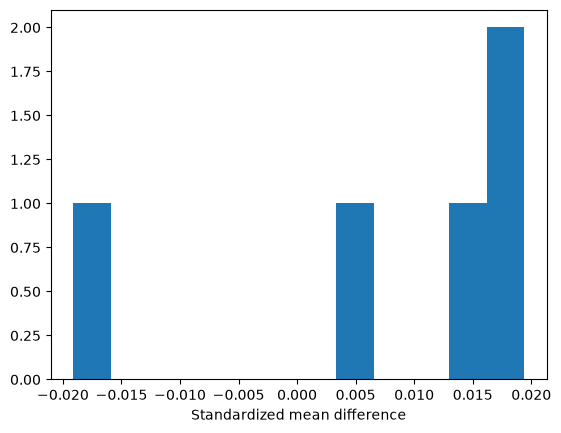

In [6]:
X = Xs['base'][train_idx]
t = T[train_idx]
pooled = np.sqrt((X[t==1].var(axis=0) + X[t==0].var(axis=0))/2)
smd = (X[t==1].mean(axis=0) - X[t==0].mean(axis=0)) / np.where(pooled > 0, pooled, 1)
display(pd.DataFrame({'feature_index':range(len(smd)), 'SMD':smd}).sort_values('SMD'))
display(df.iloc[train_idx][base_cols].isna().mean().rename('missing_rate'))
plt.hist(smd, bins=12); plt.xlabel('Standardized mean difference'); plt.show()

### ④ Conclusion — 가설 판정
두 처치군이 존재하고 동일 고객이 분할을 넘지 않는지 확인합니다. 큰 SMD·결측은 조정 필요성의 근거이며 인과 식별 확정은 아닙니다.

In [7]:
print('균형 진단:', '주의 필요' if np.max(np.abs(smd)) > .1 else '관측 기본 특성에서 큰 불균형 없음')

균형 진단: 관측 기본 특성에서 큰 불균형 없음


## STEP 3. Basic Causal Inference / ATE·회귀·IPW·DoWhy

### ① Hypothesis — 실행 전
평균 처치효과가 양수인가? 단순 차이와 조정 추정의 방향이 일치하는가?

### ② Implementation — 원리와 코드
단순 차이는 처치군과 대조군 결과율의 차이입니다. Outcome Regression은 모든 평가 고객의 μ₁(X)−μ₀(X)를 평균합니다. IPW는 처치확률 e(X) 역수로 관측 결과를 재가중합니다. DR/AIPW는 결과 회귀와 IPW 잔차 보정을 결합합니다. e는 Train에서 적합하고 [0.03, 0.97]로 제한합니다. 이는 극단 가중치를 줄이지만 편향을 유발할 수 있습니다.

DoWhy는 사전 특성 X→T, X→Y와 T→Y를 가정하고 backdoor 식별 및 선형 회귀를 수행합니다. 원 실습의 Model–Identify–Estimate 흐름을 따르며 식별 성공은 이 DAG와 누락 교란 없음이라는 가정 아래의 결과입니다. 이 단계는 Validation에서 수행하여 기본 Test를 보존합니다.

In [8]:
analysis_set = 'expanded' if 'expanded' in Xs else 'base'
nuisance = fit_nuisance(Xs[analysis_set][train_idx], T[train_idx], Y[train_idx], seed=SEED)
v = val_idx
nv = nuisance_scores(nuisance, Xs[analysis_set][v], T[v], Y[v])
t, y = T[v], Y[v]
naive = y[t==1].mean() - y[t==0].mean()
naive_se = np.sqrt(y[t==1].var(ddof=1)/(t==1).sum()+y[t==0].var(ddof=1)/(t==0).sum())
z = t*y/nv['e'] - (1-t)*y/(1-nv['e'])
ate_table = pd.DataFrame({'ATE':[naive, np.mean(nv['mu1']-nv['mu0']), z.mean(), nv['dr'].mean()]},
                         index=['Difference in means','Outcome regression','IPW','AIPW'])
ate_table.loc['Difference in means','lo'] = naive - 1.96*naive_se
ate_table.loc['Difference in means','hi'] = naive + 1.96*naive_se
for name, values in [('IPW',z),('AIPW',nv['dr'])]:
    se = values.std(ddof=1)/np.sqrt(len(values))
    ate_table.loc[name,['lo','hi']] = [values.mean()-1.96*se, values.mean()+1.96*se]
# DoWhy uses a transparent small linear adjustment model on Train only.
cf = pd.DataFrame(Xs['base'][train_idx], columns=[f'x{i}' for i in range(Xs['base'].shape[1])])
# Centering tests linear dependence alongside the intercept. Remove redundant
# dummy columns only for the DoWhy linear model; keep all ML inputs unchanged.
keep = []
centered = cf - cf.mean()
for column in cf.columns:
    if np.linalg.matrix_rank(centered[keep + [column]].to_numpy()) > len(keep):
        keep.append(column)
cf = cf[keep]
cc = list(cf.columns)
cf['treatment'], cf['outcome'] = T[train_idx], Y[train_idx]
causal_model = CausalModel(data=cf, treatment='treatment', outcome='outcome', common_causes=cc)
estimand = causal_model.identify_effect(proceed_when_unidentifiable=False)
estimate = causal_model.estimate_effect(estimand, method_name='backdoor.linear_regression', target_units='ate')
print(estimand)
print('DoWhy Train linear adjusted ATE:', float(estimate.value))

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                              
────────────(E[outcome|x0,x4,x2,x1])
d[treatment]                        
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→outcome then P(outcome|treatment,x0,x4,x2,x1,U) = P(outcome|treatment,x0,x4,x2,x1)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
     d                              
────────────(E[outcome|x0,x4,x2,x1])
d[treatment]                        
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→outcome then P(outcome|treatment,x0,x4,x2,x1,U) = P(outcome|treatment,x0,x4,x2,x1)

DoWhy Train linear adjusted ATE: 0.03237861322953006


### ③ Results — 결과 확인
구간이 없는 Outcome Regression·DoWhy 점 추정만으로 유의성을 주장하지 않습니다. DoWhy는 Train, 나머지는 Validation이므로 수치 차이는 방법과 평가 모집단 차이가 함께 작용합니다.

,ATE,lo,hi
Difference in means,0.033058,0.011762,0.054355
Outcome regression,0.032470,NaN,NaN
IPW,0.030994,-0.003428,0.065417
AIPW,0.028660,0.009689,0.047630


propensity min/max: 0.4582828267138223 0.5497015544599928
clip boundary share: 0.0


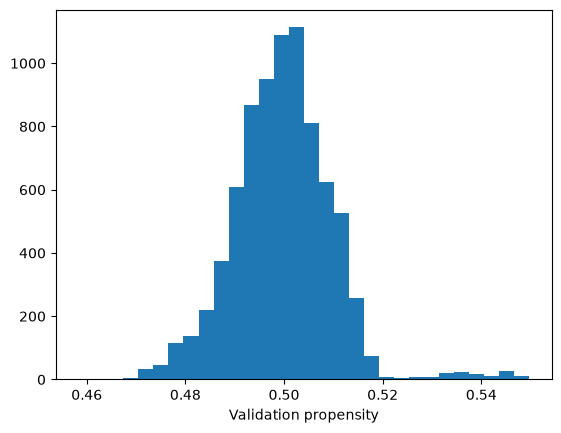

In [9]:
display(ate_table)
print('propensity min/max:', nv['e'].min(), nv['e'].max())
print('clip boundary share:', np.mean((nv['e'] <= .03) | (nv['e'] >= .97)))
plt.hist(nv['e'], bins=30); plt.xlabel('Validation propensity'); plt.show()

### ④ Conclusion — 가설 판정
평균 효과의 방향과 CI를 기록합니다. 전체 평균이 양수여도 모든 고객의 효과가 양수라는 뜻은 아닙니다. 조정해도 미관측 교란과 선택 편향 문제는 남습니다.

In [10]:
print('ATE > 0 진단:', verdict(*ate_table.loc['AIPW',['lo','hi']]))

ATE > 0 진단: 지지


## STEP 4. Causal ML / S·T·X-Learner

### ① Hypothesis — 실행 전
사전 특성으로 효과의 차이를 예측할 수 있는가? Validation Qini가 가장 높은 학습기를 사전에 정한 선택 규칙으로 고른다.

### ② Implementation — 원리와 코드
S는 X와 T를 한 모델에 넣고 T=1/0 예측 차이를 계산합니다. T는 처치군별 결과 모델 두 개를 만듭니다. X는 T의 예측으로 반사실을 대입한 효과를 각 군에서 학습하고 propensity로 결합합니다. 기본 학습기는 동일한 HistGradientBoosting 회귀로 고정합니다. 이진 결과에서도 회귀값을 사용하므로 개별 예측은 확률 경계를 벗어날 수 있습니다.

모든 학습은 Train, 모델 선택은 Validation만 사용합니다. RetailHero의 주 비교는 선택 결과와 무관하게 사전 고정한 T-Learner의 피처 차이입니다.

In [11]:
models, validation_scores, validation_rows = {}, {}, []
for feature_set, Xall in Xs.items():
    fitted = fit_meta(Xall[train_idx], T[train_idx], Y[train_idx], seed=SEED)
    for learner, model in fitted.items():
        key = feature_set + '/' + learner
        models[key] = model
        score = model.predict(Xall[val_idx])
        validation_scores[key] = score
        row = evaluate(score, T[v], Y[v], nv['e'], nv['mu0'], nv['mu1'], k=K)
        validation_rows.append({'model':key, **row})
validation_table = pd.DataFrame(validation_rows).set_index('model')
selected = validation_table.Qini.idxmax()
print('Validation에서 고정한 선택 모델:', selected)

Validation에서 고정한 선택 모델: base/S


### ③ Results — 결과 확인
모델 성능뿐 아니라 피처·학습기별 차이를 확인합니다.

In [12]:
display(validation_table.sort_values('Qini', ascending=False))

,AUUC,Qini,Uplift@30%,IncrementalRate,PolicyValue,RandomValue,PolicyGain
model,,,,,,,
base/S,0.021308,0.005811,0.046879,0.013680,0.613340,0.611181,0.002159
base/T,0.018409,0.002912,0.049794,0.011112,0.617120,0.611181,0.005939
base/X,0.017217,0.001720,0.060168,0.007922,0.619283,0.611181,0.008101
expanded/X,0.015984,0.000487,0.046607,0.006236,0.614687,0.611181,0.003506
expanded/T,0.014426,-0.001071,0.024926,0.004014,0.608568,0.611181,-0.002614
expanded/S,0.012698,-0.002799,0.021979,-0.002799,0.610003,0.611181,-0.001179


### ④ Conclusion — 가설 판정
Validation의 선택은 최종 가설 판정이 아닙니다. 선택 이후 H1 기준·모델·비율 K를 바꾸지 않습니다.

In [13]:
print('선택 고정:', selected)

선택 고정: base/S


## STEP 5. Evaluation / 독립 Test와 불확실성

### ① Hypothesis — 실행 전
Validation에서 고른 순위가 Test에서도 추가 성과를 만드는가? 주 지표 차이를 paired bootstrap으로 검증한다.

### ② Implementation — 원리와 코드
이 노트북의 AUUC 정의는 IPW 변환 결과 z=T·Y/e−(1−T)·Y/(1−e)를 점수 순서대로 누적하고 전체 n으로 나눈 gain curve를 선택 비율 q에 대해 적분한 값입니다. Qini는 같은 면적에서 무작위 기준선 q·mean(z)의 면적을 뺍니다. 구현마다 정규화가 다르므로 다른 라이브러리의 숫자와 바로 비교하지 않습니다.

Uplift@30%는 선택 고객 내부의 단순 처치·대조 결과율 차이(관측 진단)입니다. IncrementalRate는 전체 모집단당 상위 30%의 IPW 증분 성과입니다. PolicyValue는 AIPW 기반 배정 정책의 평균 결과이고 RandomValue는 확률 K의 무작위 정책 기대값입니다. **PolicyGain**은 두 값의 차이로, 동일 예산 대비 개선입니다.

평가 모델·결과 모델·성향 모델은 Test의 처치·결과를 학습에 사용하지 않습니다. 고객 단위 동일 재표집으로 순위와 상위 집합을 다시 계산합니다.

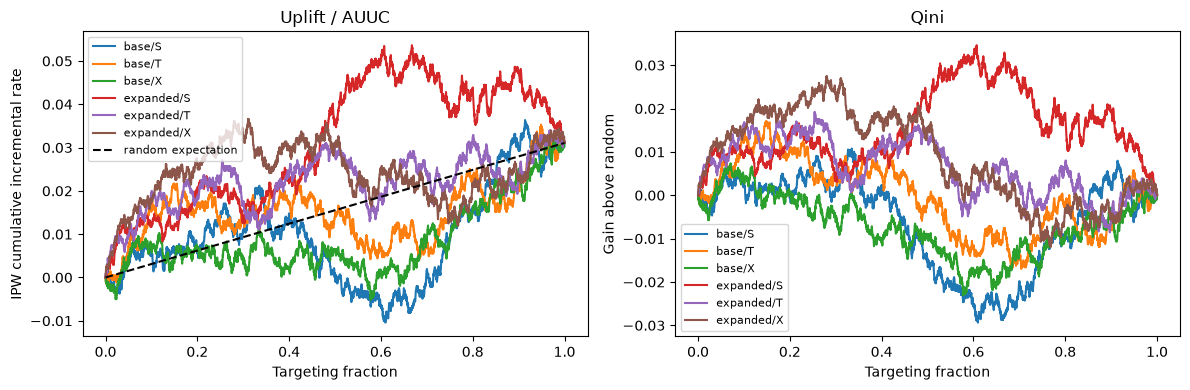

In [14]:
i = test_idx
nt = nuisance_scores(nuisance, Xs[analysis_set][i], T[i], Y[i])
test_scores = {key: model.predict(Xs[key.split('/')[0]][i]) for key,model in models.items()}
test_table = pd.DataFrame({key:evaluate(score,T[i],Y[i],nt['e'],nt['mu0'],nt['mu1'],k=K) for key,score in test_scores.items()}).T
# Fixed plotting order is unrelated to outcomes. Main comparisons are frozen in STEP 1.
fig, axes = plt.subplots(1,2,figsize=(12,4))
z = T[i]*Y[i]/nt['e'] - (1-T[i])*Y[i]/(1-nt['e'])
q = np.arange(len(i)+1)/len(i)
for key, score in test_scores.items():
    tie = np.random.default_rng(SEED).random(len(score))
    order = np.lexsort((tie,-score))
    gain = np.r_[0,np.cumsum(z[order])/len(i)]
    axes[0].plot(q,gain,label=key)
    axes[1].plot(q,gain-q*z.mean(),label=key)
axes[0].plot(q,q*z.mean(),'k--',label='random expectation')
axes[0].set(xlabel='Targeting fraction',ylabel='IPW cumulative incremental rate',title='Uplift / AUUC')
axes[1].set(xlabel='Targeting fraction',ylabel='Gain above random',title='Qini')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### ③ Results — 결과 확인
개별 모델의 Test 점수는 보조 비교입니다. 판정은 사전 고정한 한 가지 차이에만 적용합니다.

In [15]:
display(test_table)
# Conditional evaluation CIs for the validation-selected model; no refitting.
rng = np.random.default_rng(SEED)
metric_draws = []
for _ in range(B):
    b = rng.integers(0,len(i),len(i))
    metric_draws.append(evaluate(test_scores[selected][b],T[i][b],Y[i][b],nt['e'][b],nt['mu0'][b],nt['mu1'][b],k=K))
metric_draws = pd.DataFrame(metric_draws)
selected_ci = pd.DataFrame({'estimate':test_table.loc[selected],
                            'lo':metric_draws.quantile(.025), 'hi':metric_draws.quantile(.975)})
display(selected_ci)
test_table.to_csv(OUT / 'test_metrics.csv')
selected_ci.to_csv(OUT / 'selected_metric_ci.csv')

,AUUC,Qini,Uplift@30%,IncrementalRate,PolicyValue,RandomValue,PolicyGain
base/S,0.009528,-0.006009,0.008917,0.010885,0.603736,0.610227,-0.006491
base/T,0.015131,-0.000405,0.019284,0.013144,0.602691,0.610227,-0.007536
base/X,0.008603,-0.006933,-0.003223,0.003111,0.597618,0.610227,-0.012609
expanded/S,0.030958,0.015422,0.051335,0.014009,0.612593,0.610227,0.002366
expanded/T,0.021962,0.006426,0.036148,0.017107,0.609452,0.610227,-0.000774
expanded/X,0.024200,0.008664,0.072028,0.032596,0.615653,0.610227,0.005426


,estimate,lo,hi
AUUC,0.009528,-0.022624,0.034100
Qini,-0.006009,-0.018880,0.007132
Uplift@30%,0.008917,-0.051320,0.055007
IncrementalRate,0.010885,-0.014027,0.033861
PolicyValue,0.603736,0.579869,0.625648
RandomValue,0.610227,0.595820,0.626950
PolicyGain,-0.006491,-0.021072,0.003697


### ④ Conclusion — 가설 판정
테스트 점수를 보고 모델·특성을 다시 선택하면 선택 편향이 생깁니다. 여기서는 Validation 선택을 유지하고 다음 단계에서 고정 비교의 CI를 계산합니다.

## STEP 6. Hypothesis Test / H1 최종 판정

### ① Hypothesis — 실행 전
H1: 과거 구매 이력을 추가한 **고정 T-Learner**의 테스트 Qini가 기본 고객 정보 T-Learner보다 높다.

### ② Implementation — 원리와 코드
Test를 한 번 사용해 사전 기준을 적용합니다. 0 포함은 증거 불충분이므로 판단 보류이며 효과가 없다는 증명은 아닙니다.

In [16]:
h1 = paired_bootstrap(test_scores['expanded/T'], test_scores['base/T'], T[i],Y[i],nt['e'],nt['mu0'],nt['mu1'],metric='Qini',B=B,seed=SEED)

### ③ Results — 결과 확인
효과 차이와 95% 신뢰구간을 원 단위(결과 발생 확률)로 읽습니다. 0.01은 1%p입니다.

In [17]:
display(pd.Series(h1, name='H1 comparison'))

estimate    0.006831
lo         -0.010136
hi          0.025118
Name: H1 comparison, dtype: float64

### ④ Conclusion — 가설 판정
아래 판정은 실행한 표본·분할·고정 모델에 한정됩니다. 제한된 표본에서 나온 반대 근거를 모든 알고리즘에 일반화하지 않습니다.

In [18]:
h1_verdict = verdict(h1['lo'],h1['hi'])
display(Markdown(f'**H1 판정: {h1_verdict}** — 차이 {h1["estimate"]:.6f}, 95% CI [{h1["lo"]:.6f}, {h1["hi"]:.6f}].'))

**H1 판정: 판단 보류** — 차이 0.006831, 95% CI [-0.010136, 0.025118].

## STEP 7. Advanced / H2·DML·DR·예산 정책

### ① Hypothesis — 실행 전
H2(후속): cross-fitting으로 학습한 DR-Learner는 고정된 기존 선택 모델보다 Qini가 높다. H1 결과를 확인한 뒤 이 가설을 기록하고, 아직 사용하지 않은 advanced holdout으로만 비교한다.

### ② Implementation — 원리와 코드
H1과 Validation에서 모델/피처 성능이 달라질 수 있다는 결과를 출발점으로 학습 방법을 바꿉니다. H2 주 지표는 DR−기존 선택 모델의 Qini 차이, 동일한 95% 구간 판정입니다. 다중 탐색 전체의 오류율을 통제한 확증 연구는 아닙니다.

DR-Learner는 3-fold cross-fitting으로 자기 결과를 학습하지 않은 nuisance 예측을 만들고 AIPW 의사결과를 X에 회귀합니다. DML은 Y와 T의 교차 적합 잔차를 회귀해 상수 처치효과를 추정하는 PLR 모형입니다. 상수 효과라는 별도 가정이 필요하며 CATE 순위 모델과 직접 비교하지 않습니다.

예산 곡선은 holdout에 여러 K를 적용한 탐색 결과이며 최적 K의 확증 검증은 아닙니다. 실제 비용·마진이 없어 정책 가치는 결과 확률 단위로만 보고합니다.

In [19]:
print('H2 등록 근거: H1 판정 =', h1_verdict, '; Validation Qini 범위 =', validation_table.Qini.min(), validation_table.Qini.max())
H2 = 'DR-Learner의 advanced holdout Qini가 validation 선택 기존 모델보다 높다.'
print('미사용 holdout을 열기 전 H2:', H2)
advanced_models = fit_advanced(Xs[analysis_set][train_idx],T[train_idx],Y[train_idx],seed=SEED)
a = advanced_idx
na = nuisance_scores(nuisance,Xs[analysis_set][a],T[a],Y[a])
dr_score = advanced_models['DR'].predict(Xs[analysis_set][a])
old_score = models[selected].predict(Xs[selected.split('/')[0]][a])
h2 = paired_bootstrap(dr_score,old_score,T[a],Y[a],na['e'],na['mu0'],na['mu1'],metric='Qini',B=B,seed=SEED+1)

H2 등록 근거: H1 판정 = 판단 보류 ; Validation Qini 범위 = -0.002798866961015974 0.005811254468016799
미사용 holdout을 열기 전 H2: DR-Learner의 advanced holdout Qini가 validation 선택 기존 모델보다 높다.


### ③ Results — 결과 확인
DML은 평균 효과 추정, DR는 타기팅 순위를 위한 CATE 추정으로 구분합니다.

DML constant-effect estimate / SE: {'estimate': 0.030266091332123764, 'se': 0.005564237228827839}


estimate    0.007536
lo         -0.012568
hi          0.025446
Name: H2 Qini difference, dtype: float64

,fraction,PolicyValue,RandomValue,PolicyGain
0,0.1,0.602710,0.601769,0.000941
1,0.2,0.609654,0.605381,0.004272
2,0.3,0.608334,0.608994,-0.000660
3,0.5,0.614298,0.616219,-0.001920
4,1.0,0.634281,0.634281,0.000000


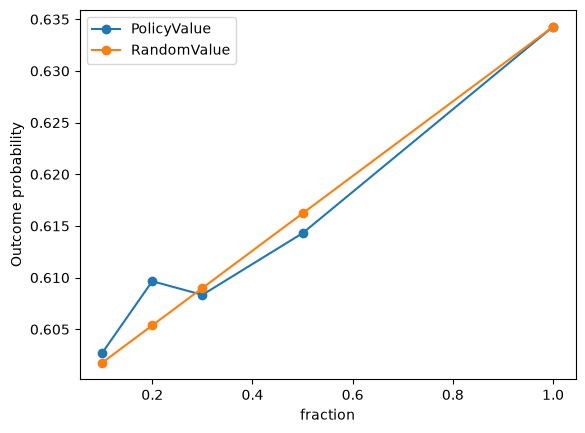

In [20]:
print('DML constant-effect estimate / SE:', advanced_models['DML'])
display(pd.Series(h2,name='H2 Qini difference'))
budget_table = pd.DataFrame([{'fraction':k,**evaluate(dr_score,T[a],Y[a],na['e'],na['mu0'],na['mu1'],k=k)} for k in [.1,.2,.3,.5,1.]])
display(budget_table[['fraction','PolicyValue','RandomValue','PolicyGain']])
budget_table.plot(x='fraction',y=['PolicyValue','RandomValue'],marker='o'); plt.ylabel('Outcome probability'); plt.show()

### ④ Conclusion — 가설 판정
H2도 동일한 CI 규칙으로 판정합니다. 정책 비용 최적화와 표본 크기 안정성 실험은 새 검증 표본·사전 가설을 확보한 뒤 진행합니다.

In [21]:
h2_verdict = verdict(h2['lo'],h2['hi'])
display(Markdown(f'**H2 판정: {h2_verdict}** — Qini 차이 {h2["estimate"]:.6f}, 95% CI [{h2["lo"]:.6f}, {h2["hi"]:.6f}].'))
summary = {'dataset':DATA.name,'selected':selected,'H1':H1,'H1_result':h1,'H1_verdict':h1_verdict,
           'H2':H2,'H2_result':h2,'H2_verdict':h2_verdict,'preparation':preparation}
(OUT / 'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str))
display(pd.Series(summary))

**H2 판정: 판단 보류** — Qini 차이 0.007536, 95% CI [-0.012568, 0.025446].

dataset                                               retailhero
selected                                                  base/S
H1             H1: 과거 구매 이력을 추가한 **고정 T-Learner**의 테스트 Qini가 ...
H1_result      {'estimate': 0.006830982250230145, 'lo': -0.01...
H1_verdict                                                 판단 보류
H2             DR-Learner의 advanced holdout Qini가 validation ...
H2_result      {'estimate': 0.007536374906875341, 'lo': -0.01...
H2_verdict                                                 판단 보류
preparation    {'history_reference': '2019-03-19 00:00:00', '...
dtype: object

## 해석의 한계와 다음 가설

초기 H1과 결과 확인 후 설정한 H2는 서로 다른 holdout에서 판정했습니다. 부트스트랩 CI는 같은 고객 표본의 결과와 고정된 nuisance/model에 조건부입니다. 관측되지 않은 교란, 공개 데이터의 선택 과정, 모델 오지정, 다른 시점·채널로의 일반화는 이 구간에 포함되지 않습니다.

다음 실험 후보는 학습 표본 크기를 바꾼 안정성 비교, propensity clipping 민감도, 구매당 마진·발송비를 가정한 정책 비용 분석입니다. Criteo의 conversion 확장은 visit보다 희소한 별도 outcome이므로 검정력과 별도 holdout을 먼저 설계합니다. 여기서 추가 결과를 몰래 H1에 포함하지 않습니다.

## 참고 자료

- 원 실습: `references/ML_for_Causal_Inference.ipynb`
- [DoWhy: 식별과 추정](https://www.pywhy.org/dowhy/main/user_guide/causal_tasks/estimating_causal_effects/index.html)
- [Meta-learners: S/T/X](https://econml.azurewebsites.net/spec/estimation/metalearners.html)
- [Double Machine Learning](https://econml.azurewebsites.net/spec/estimation/dml.html)
- [Doubly Robust Learning](https://econml.azurewebsites.net/spec/estimation/dr.html)
- [RetailHero 공식 설명](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data)
- [Criteo 데이터 카드](https://huggingface.co/datasets/criteo/criteo-uplift)